<a href="https://colab.research.google.com/github/Deangr-econ/Asset_Pricing_Start_Project/blob/main/Asset_Pricing_Start_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

cov = pd.read_csv("/content/drive/Othercomputers/My Laptop/Documents/Maastricht University/Master/Thesis/Volare Data/realized_covariance_stocks_20261030/realized_covariance_stocks_20261030.csv")
cov['date'] = pd.to_datetime(cov['date'])
cov.info()
print(f"Nan-Values:",cov.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2439500 entries, 0 to 2439499
Data columns (total 9 columns):
 #   Column    Dtype         
---  ------    -----         
 0   date      datetime64[ns]
 1   asset1    object        
 2   asset2    object        
 3   rcov      float64       
 4   rbpcov    float64       
 5   rscov_p   float64       
 6   rscov_n   float64       
 7   rscov_mp  float64       
 8   rscov_mn  float64       
dtypes: datetime64[ns](1), float64(6), object(2)
memory usage: 167.5+ MB
Nan-Values: 0


In [ ]:
import torch

# 1. Identify unique dates and unique assets in the dataset
unique_dates = sorted(cov['date'].unique())
unique_assets = sorted(list(set(cov['asset1']).union(set(cov['asset2']))))

T = len(unique_dates)
N = len(unique_assets)

# Create a mapping from asset name to index for fast lookup
asset_to_idx = {asset: idx for idx, asset in enumerate(unique_assets)}

# 2. Pivot the DataFrame to align asset1 and asset2 pairs for each date
# This creates a structured table where we can easily extract the NxN matrix per date
pivoted = cov.pivot_table(index='date', columns=['asset1', 'asset2'], values='rcov')

# 3. Pre-allocate the NumPy array for the [T, N, N] tensor
cov_matrices_np = np.zeros((T, N, N))

# 4. Fill the 3D array ensuring symmetry
for t_idx, date in enumerate(unique_dates):
    if date in pivoted.index:
        date_series = pivoted.loc[date]
        # date_series has a MultiIndex of (asset1, asset2)
        for (a1, a2), val in date_series.items():
            if not pd.isna(val):
                i, j = asset_to_idx[a1], asset_to_idx[a2]
                cov_matrices_np[t_idx, i, j] = val
                cov_matrices_np[t_idx, j, i] = val  # Ensure symmetry

# 5. Convert to PyTorch tensor
cov_tensor = torch.tensor(cov_matrices_np, dtype=torch.float64)

print(f"Tensor Shape: {cov_tensor.shape} (Dates: {T}, Assets: {N} x {N})")
print("First Covariance Matrix (t=0):\n", cov_tensor[0])

Tensor Shape: torch.Size([2975, 40, 40]) (Dates: 2975, Assets: 40 x 40)
First Covariance Matrix (t=0):
 tensor([[2.7493e-04, 8.6404e-05, 7.5425e-05,  ..., 3.8313e-05, 4.4625e-05,
         4.9021e-05],
        [8.6404e-05, 1.4251e-04, 5.7479e-05,  ..., 4.4823e-05, 3.8804e-05,
         3.8051e-05],
        [7.5425e-05, 5.7479e-05, 1.7887e-03,  ..., 1.3890e-05, 9.4261e-06,
         5.1623e-05],
        ...,
        [3.8313e-05, 4.4823e-05, 1.3890e-05,  ..., 9.3222e-05, 3.1706e-05,
         3.3762e-05],
        [4.4625e-05, 3.8804e-05, 9.4261e-06,  ..., 3.1706e-05, 8.0246e-05,
         2.0592e-05],
        [4.9021e-05, 3.8051e-05, 5.1623e-05,  ..., 3.3762e-05, 2.0592e-05,
         1.5955e-04]], dtype=torch.float64)


In [ ]:
import yfinance as yf
import pandas as pd
import torch

# 1. Define period parameters based on cov dates
start_date = unique_dates[0]
end_date = unique_dates[-1]
print(f"Target Period: {start_date} to {end_date}")

# Go back 5 days to safely catch the prior trading day's close price (handling weekends/holidays)
download_start = str(pd.to_datetime(start_date) - pd.Timedelta(days=5)).split()[0]
download_end = str(pd.to_datetime(end_date) + pd.Timedelta(days=1)).split()[0]

# 2. Download historical close prices for the 40 assets starting earlier
stock_data = yf.download(unique_assets, start=download_start, end=download_end, interval="1d", auto_adjust=True)
close_prices = stock_data['Close']

# Check for NaN values in raw stock prices
print('NaN-Values in Stock Prices (close_prices):', close_prices.isna().sum().sum())

# 3. Download the risk-free rate proxy
rf_data = yf.download("^IRX", start=download_start, end=download_end, interval="1d", auto_adjust=True)['Close']
# Convert annual percentage yield to a daily decimal rate proxy and squeeze to a Series
rf_daily = (rf_data / (252 * 100)).squeeze()

# Align indices
rf_daily = rf_daily.reindex(close_prices.index, method='ffill')

# 4. Calculate daily close-to-close returns
stock_returns_all = close_prices.pct_change()

# 5. Compute daily excess returns
# Subtract the 1D Series of daily rf from each column of stock_returns_all
excess_returns_all = stock_returns_all.subtract(rf_daily, axis=0)

# 6. Slice excess returns to match the target covariance unique_dates exactly
excess_returns = excess_returns_all.loc[start_date:end_date]
stock_returns = stock_returns_all.loc[start_date:end_date]

print("\nExcess Returns Shape:", excess_returns.shape)
print("\nFirst 5 rows of Excess Returns (including the original start date):")
print(excess_returns.head())

# Keep the NaN check in sliced excess returns
print('\nNan-Values in sliced Excess Returns:', excess_returns.isna().sum().sum())

# 7. Convert excess returns to a PyTorch tensor with dimensions [Time, Stock, Return_Dim]
# Base shape: [Time, Stock] -> unsqueeze(-1) -> [Time, Stock, 1]
excess_returns_tensor = torch.tensor(excess_returns.values, dtype=torch.float64).unsqueeze(-1)
print("\nExcess Returns Tensor Shape:", excess_returns_tensor.shape)

Target Period: 2015-01-02 00:00:00 to 2026-10-30 00:00:00


[*********************100%***********************]  40 of 40 completed
[*********************100%***********************]  1 of 1 completed

NaN-Values in Stock Prices (close_prices): 0

Excess Returns Shape: (2975, 40)

First 5 rows of Excess Returns (including the original start date):
Ticker          AAPL      ADBE           AMD      AMGN      AMZN       AXP  \
Date                                                                         
2015-01-02 -0.009513 -0.004952 -5.952381e-07  0.003766 -0.005897 -0.000216   
2015-01-05 -0.028172 -0.004977 -3.745434e-03 -0.011883 -0.020517 -0.026446   
2015-01-06  0.000094 -0.020145 -1.127898e-02 -0.032218 -0.022834 -0.021313   
2015-01-07  0.014021  0.008223 -1.901227e-02  0.034924  0.010599  0.021840   
2015-01-08  0.038422  0.025453  1.162718e-02 -0.003603  0.006835  0.014174   

Ticker            BA       CAT       CRM      CSCO  ...        PG        PM  \
Date                                                ...                       
2015-01-02 -0.000231  0.003823 -0.001181 -0.000724  ... -0.007136 -0.005280   
2015-01-05 -0.006926 -0.052786 -0.018062 -0.019920  ... -0.004755 -0

In [ ]:
T, N, _ = cov_tensor.shape

# Create ones of shape (T, N, 1) on the same device/dtype as cov_tensor
ones = torch.ones((T, N, 1), dtype=cov_tensor.dtype, device=cov_tensor.device)

# Batched solve: solves cov_tensor[t] @ x[t] = ones[t] for all t simultaneously
x = torch.linalg.solve(cov_tensor, ones)  # shape: (T, N, 1)

# Normalize along the asset dimension (dim=1) and squeeze to shape (T, N)
target_weights = (x / x.sum(dim=1, keepdim=True)).squeeze(-1)

# Retrieve the correct 2D excess returns of shape (T, N) from excess_returns_tensor
r_excess = excess_returns_tensor.squeeze(-1)

# Out-of-sample portfolio excess returns (t=0 weights applied to t=1 returns)
port_excess_returns = (target_weights[:-1] * r_excess[1:]).sum(dim=1)

print(f"Target Weights Tensor Shape: {target_weights.shape}")
print(f"Portfolio Excess Returns Shape: {port_excess_returns.shape}")
print("First 5 out-of-sample portfolio returns:", port_excess_returns[:5])

Target Weights Tensor Shape: torch.Size([2975, 40])
Portfolio Excess Returns Shape: torch.Size([2974])
First 5 out-of-sample portfolio returns: tensor([-0.0140,  0.0044,  0.0093,  0.0152, -0.0048], dtype=torch.float64)


=== PORTFOLIO PERFORMANCE METRICS ===
Trading Days Analysed: 2974
Annualized Return:    11.21%
Annualized Volatility:13.01%
Sharpe Ratio:         0.8619
Cumulative Return:    239.81%
Maximum Drawdown:     -25.94%


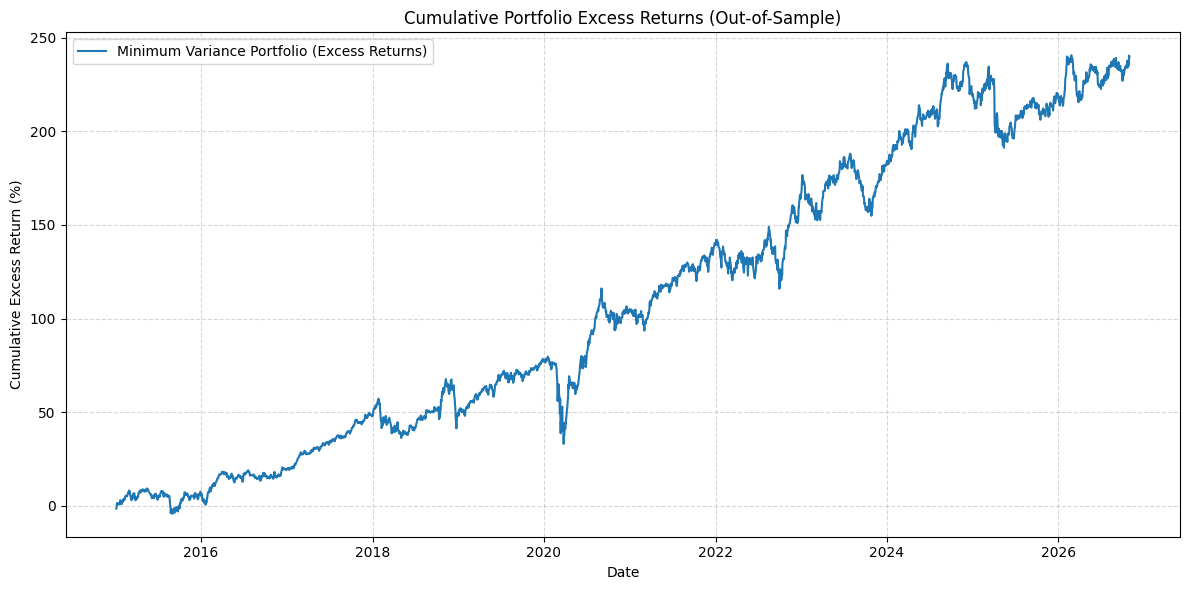

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Convert portfolio returns to a numpy array
returns_np = port_excess_returns.detach().cpu().numpy()

# Calculate metrics assuming 252 trading days per year
num_days = len(returns_np)
ann_factor = 252

# 1. Average Daily & Annualized Return
avg_daily_return = np.mean(returns_np)
avg_ann_return = avg_daily_return * ann_factor

# 2. Annualized Volatility
ann_volatility = np.std(returns_np, ddof=1) * np.sqrt(ann_factor)

# 3. Sharpe Ratio (using excess returns, so risk-free rate is already subtracted)
sharpe_ratio = avg_ann_return / ann_volatility if ann_volatility > 0 else 0.0

# 4. Cumulative Returns
# Since these are daily simple excess returns, we calculate cumulative returns via compounding:
cum_returns = np.cumprod(1 + returns_np) - 1
final_cum_return = cum_returns[-1]

# 5. Maximum Drawdown
running_max = np.maximum.accumulate(1 + cum_returns)
drawdowns = ((1 + cum_returns) - running_max) / running_max
max_drawdown = np.min(drawdowns)

print("=== PORTFOLIO PERFORMANCE METRICS ===")
print(f"Trading Days Analysed: {num_days}")
print(f"Annualized Return:    {avg_ann_return:.2%}")
print(f"Annualized Volatility:{ann_volatility:.2%}")
print(f"Sharpe Ratio:         {sharpe_ratio:.4f}")
print(f"Cumulative Return:    {final_cum_return:.2%}")
print(f"Maximum Drawdown:     {max_drawdown:.2%}")

# 6. Plot the Cumulative Return Path
plot_dates = unique_dates[1:]  # Out-of-sample returns correspond to t=1 to end
plt.figure(figsize=(12, 6))
plt.plot(plot_dates, cum_returns * 100, label="Minimum Variance Portfolio (Excess Returns)", color="tab:blue")
plt.title("Cumulative Portfolio Excess Returns (Out-of-Sample)")
plt.xlabel("Date")
plt.ylabel("Cumulative Excess Return (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

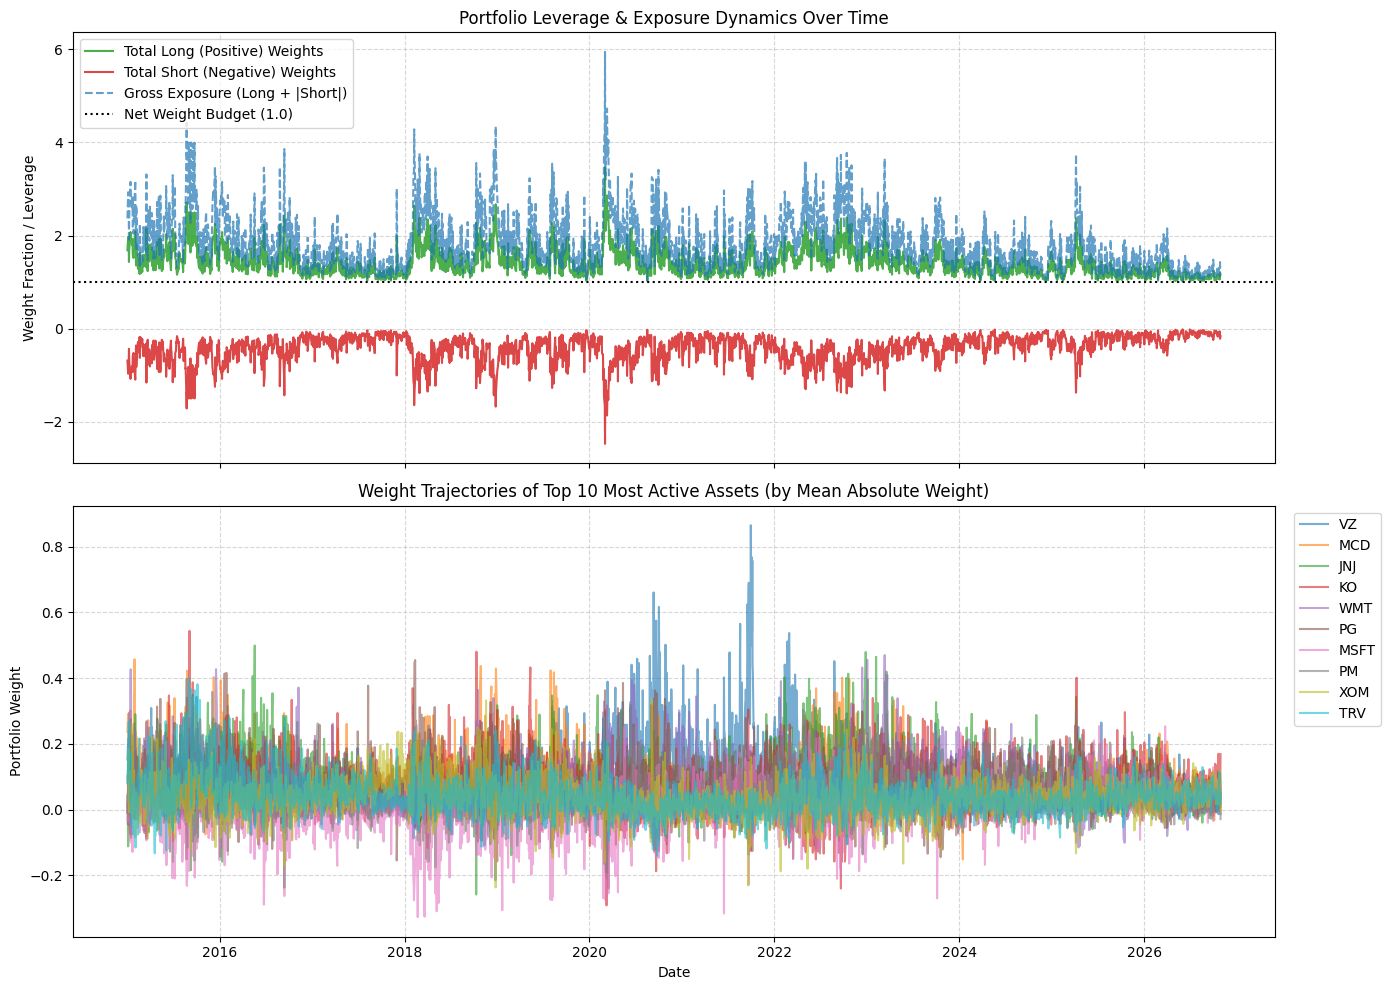

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Convert target_weights tensor to a numpy array (T, N)
weights_np = target_weights.detach().cpu().numpy()

# Create a DataFrame for easier handling with dates
weights_df = pd.DataFrame(weights_np, index=unique_dates, columns=unique_assets)

# Compute portfolio structure characteristics over time using correct pandas method fillna
long_exposure = weights_df[weights_df > 0].fillna(0).sum(axis=1)
short_exposure = weights_df[weights_df < 0].fillna(0).sum(axis=1)
gross_exposure = long_exposure + short_exposure.abs()

# Create the plots
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plot 1: Overall Portfolio Leverage & Exposure (Long vs Short)
axes[0].plot(weights_df.index, long_exposure, label="Total Long (Positive) Weights", color="tab:green", alpha=0.85)
axes[0].plot(weights_df.index, short_exposure, label="Total Short (Negative) Weights", color="tab:red", alpha=0.85)
axes[0].plot(weights_df.index, gross_exposure, label="Gross Exposure (Long + |Short|)", color="tab:blue", linestyle="--", alpha=0.7)
axes[0].axhline(1.0, color="black", linestyle=":", label="Net Weight Budget (1.0)")
axes[0].set_title("Portfolio Leverage & Exposure Dynamics Over Time")
axes[0].set_ylabel("Weight Fraction / Leverage")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper left")

# Plot 2: Time series of weights of top 10 assets by average absolute weight
mean_abs_weights = weights_df.abs().mean(axis=0).sort_values(ascending=False)
top_10_assets = mean_abs_weights.index[:10]

for asset in top_10_assets:
    axes[1].plot(weights_df.index, weights_df[asset], label=asset, alpha=0.6)

axes[1].set_title("Weight Trajectories of Top 10 Most Active Assets (by Mean Absolute Weight)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Portfolio Weight")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()